# 08 — Все сделки лучших конфигураций: каждый исход по порядку

Для каждого инструмента взята лучшая конфигурация исследования «пересечение цены с быстрой MA + наклон медленной
MA» (этап 3, лучшая по IS-плато — та же, что в презентации [07](07_project_presentation.ipynb)). Ниже — все её
сделки за всю историю по порядку: вход, выход, цены, результат в долларах и тиках и накопленный итог.

* **Excel:** [`research/ma_cross_slope_5m/tables/trade_ledger.xlsx`](../research/ma_cross_slope_5m/tables/trade_ledger.xlsx).
  Листы: «Сводка», «Все сделки» (все инструменты в порядке закрытия) и по листу на инструмент. Накопленный итог,
  просадка и серии убытков — формулы.
* **CSV:** [`research/ma_cross_slope_5m/tables/trade_ledger.csv`](../research/ma_cross_slope_5m/tables/trade_ledger.csv).

**Как читать.** 1 контракт, без комиссий и проскальзывания (по ТЗ). Вход и выход — по Open свечи после сигнала;
цены — сырые цены контракта. Сделка, прошедшая через ролл, переходит в новый контракт по цене перекрытия, поэтому
её цены входа и выхода относятся к разным контрактам. **IS** — участок, на котором конфигурация выбрана, поэтому
там результат хорош по построению. Честная проверка — только **OOS** (последние 30 % истории).

In [1]:
from IPython.display import Image, display

from src.ma_slope import ledger as L
from src.ma_slope.presentation import FIGS

led = L.load_ledger()
configs = led.drop_duplicates("ticker").set_index("ticker")["config"]
print(f"Сделок всего: {len(led):,}".replace(",", " "))

Сделок всего: 16 349


## Сводка по инструментам

In [2]:
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)
L.summary_table(led)

,сделок,прибыльных,убыточных,доля прибыльных,"итого PnL, $","PnL IS, $","PnL OOS, $","средняя сделка, $","средняя сделка, тиков","лучшая, $","худшая, $",макс. убытков подряд,"макс. просадка, $"
NG,"2,944.00","1,001.00","1,898.00",0.34,"2,219.20","2,063.70",155.50,0.75,7.54,150.60,-72.70,14.00,284.70
BR (Brent),"2,479.00",938.00,"1,520.00",0.38,"2,484.20","2,441.50",42.70,1.00,10.02,168.10,-142.40,12.00,810.20
GOLD (GC),"1,612.00",585.00,"1,021.00",0.36,"2,786.85","1,431.55","1,355.30",1.73,17.29,547.90,-180.80,13.00,836.60
SILV (SI),"4,749.00","1,704.00","2,800.00",0.36,546.00,289.60,256.40,0.11,1.15,201.50,-72.80,19.00,279.60
PLT (PL),"1,819.00",749.00,"1,063.00",0.41,"4,426.50","3,461.50",965.00,2.43,24.33,498.50,-137.70,13.00,532.20
PLD (PA),"2,389.00",922.00,"1,464.00",0.39,"7,725.02","6,782.34",942.68,3.23,323.36,666.32,-140.90,18.00,737.57
COPPER (HG),159.00,68.00,91.00,0.43,48.82,43.95,4.87,0.31,30.70,11.53,-4.52,5.00,19.62
WTI (CL),198.00,99.00,98.00,0.50,122.00,178.70,-56.70,0.62,6.16,51.60,-50.40,4.00,122.50


## Все исходы по порядку

Для каждого инструмента: сверху накопленный итог по номеру сделки, снизу результат каждой сделки (синий — прибыль,
красный — убыток). Вертикальная линия — граница IS/OOS.

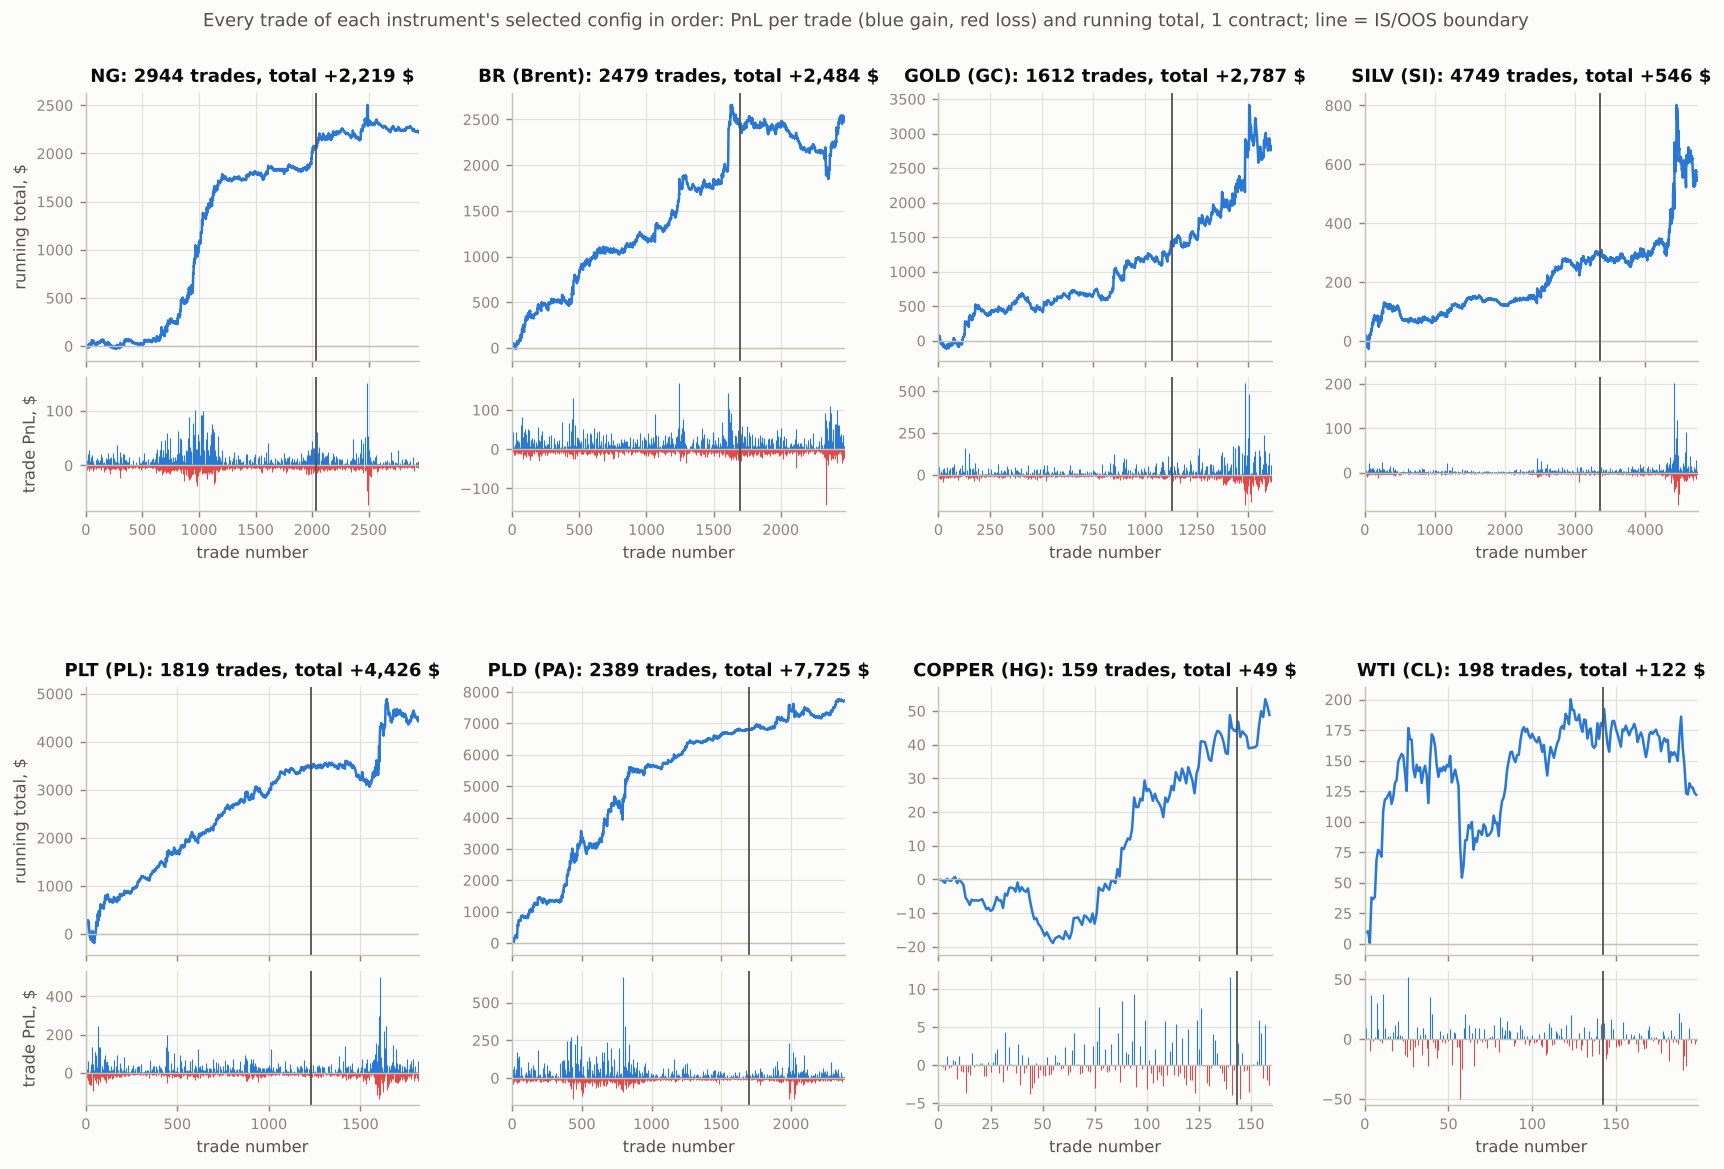

In [3]:
display(Image(filename=str(FIGS / "trade_outcomes.png")))

## Таблицы сделок

Каждая сделка по порядку. Колонки: номер, выборка, сторона, время и контракт входа, цена входа, время и контракт
выхода, цена выхода, длительность в часах, результат в долларах и в тиках, исход и накопленный итог.

### NG

In [4]:
print(configs["ng"])
print(L.format_trades(led, "ng"))

VWMA21 / EMA42, pct k=40 eps=0%, exit=slope_flip


   № выборка сторона             вход контракт цена входа            выход контракт  цена выхода часов  PnL, $    тиков   исход накопленный, $
   1      IS    Long 2020-02-04 23:40     NGG0      1.880 2020-02-05 15:50      NGG0       1.840  16.2   -4.00    -40.0  убыток          -4.00
   2      IS   Short 2020-02-05 16:10     NGG0      1.840 2020-02-05 23:10      NGG0       1.870   7.0   -3.00    -30.0  убыток          -7.00
   3      IS    Long 2020-02-07 12:00     NGG0      1.859 2020-02-07 22:35      NGG0       1.856  10.6   -0.30     -3.0  убыток          -7.30
   4      IS   Short 2020-02-10 11:30     NGG0      1.804 2020-02-11 22:50      NGG0       1.800  35.3   +0.40     +4.0 прибыль          -6.90
   5      IS    Long 2020-02-12 16:30     NGG0      1.834 2020-02-14 11:20      NGG0       1.802  42.8   -3.20    -32.0  убыток         -10.10
   6      IS   Short 2020-02-17 10:00     NGG0      1.850 2020-02-17 10:10      NGG0       1.900   0.2   -5.00    -50.0  убыток         -15.10

### BR (Brent)

In [5]:
print(configs["br"])
print(L.format_trades(led, "br"))

WMA91 / VWMA200, atr k=40 eps=0.25 atr=100, exit=slope_flip


   № выборка сторона             вход  контракт цена входа            выход контракт  цена выхода часов  PnL, $    тиков   исход накопленный, $
   1      IS    Long 2011-12-21 13:25 BRF2_2012     107.08 2011-12-23 16:35 BRF2_2012      107.44  51.2   +3.60    +36.0 прибыль          +3.60
   2      IS   Short 2011-12-23 17:45 BRF2_2012     107.67 2011-12-23 22:05 BRF2_2012      108.03   4.3   -3.60    -36.0  убыток          -0.00
   3      IS    Long 2011-12-23 22:50 BRF2_2012     107.92 2011-12-26 21:00 BRF2_2012      108.36  70.2   +4.40    +44.0 прибыль          +4.40
   4      IS   Short 2011-12-26 23:30 BRF2_2012     108.22 2011-12-27 19:50 BRF2_2012      108.65  20.3   -4.30    -43.0  убыток          +0.10
   5      IS   Short 2011-12-28 17:25 BRF2_2012     108.41 2011-12-30 14:45 BRF2_2012      107.89  45.3   +5.20    +52.0 прибыль          +5.30
   6      IS   Short 2011-12-30 19:50 BRF2_2012     107.22 2011-12-30 22:50 BRF2_2012      108.02   3.0   -8.00    -80.0  убыток        

### GOLD (GC)

In [6]:
print(configs["gold"])
print(L.format_trades(led, "gold"))

SSMA61 / VWMA206, pct k=80 eps=0.1%, exit=slope_flip


   № выборка сторона             вход  контракт цена входа            выход контракт  цена выхода часов  PnL, $    тиков   исход накопленный, $
   1      IS    Long 2011-12-21 15:10 GDH2_2012    1,633.0 2011-12-22 15:10 GDH2_2012     1,617.9  24.0  -15.10   -151.0  убыток         -15.10
   2      IS   Short 2011-12-22 16:40 GDH2_2012    1,621.0 2011-12-30 17:10 GDH2_2012     1,575.6 192.5  +45.40   +454.0 прибыль         +30.30
   3      IS    Long 2011-12-30 22:50 GDH2_2012    1,573.7 2012-01-09 20:30 GDH2_2012     1,619.5 237.7  +45.80   +458.0 прибыль         +76.10
   4      IS   Short 2012-01-10 12:15 GDH2_2012    1,621.8 2012-01-10 15:35 GDH2_2012     1,639.6   3.3  -17.80   -178.0  убыток         +58.30
   5      IS    Long 2012-01-10 22:20 GDH2_2012    1,637.9 2012-01-13 20:35 GDH2_2012     1,642.2  70.2   +4.30    +43.0 прибыль         +62.60
   6      IS   Short 2012-01-16 14:15 GDH2_2012    1,646.5 2012-01-17 11:35 GDH2_2012     1,669.5  21.3  -23.00   -230.0  убыток        

### SILV (SI)

In [7]:
print(configs["silv"])
print(L.format_trades(led, "silv"))

VWMA98 / TMA25, pct k=80 eps=0%, exit=slope_flip


   № выборка сторона             вход  контракт цена входа            выход контракт  цена выхода часов  PnL, $    тиков   исход накопленный, $
   1      IS   Short 2011-12-22 12:00 SVH2_2012      29.51 2011-12-22 12:50 SVH2_2012       29.72   0.8   -2.10    -21.0  убыток          -2.10
   2      IS    Long 2011-12-22 16:20 SVH2_2012      29.46 2011-12-22 19:05 SVH2_2012       29.33   2.8   -1.30    -13.0  убыток          -3.40
   3      IS    Long 2011-12-23 15:45 SVH2_2012      29.36 2011-12-23 23:15 SVH2_2012       29.25   7.5   -1.10    -11.0  убыток          -4.50
   4      IS   Short 2011-12-27 21:15 SVH2_2012      29.03 2011-12-29 22:30 SVH2_2012       27.50  49.2  +15.30   +153.0 прибыль         +10.80
   5      IS    Long 2012-01-03 10:05 SVH2_2012      28.50 2012-01-03 10:40 SVH2_2012       28.60   0.6   +1.00    +10.0 прибыль         +11.80
   6      IS    Long 2012-01-04 10:45 SVH2_2012      29.49 2012-01-04 15:15 SVH2_2012       29.45   4.5   -0.40     -4.0  убыток        

### PLT (PL)

In [8]:
print(configs["plt"])
print(L.format_trades(led, "plt"))

TMA20 / VWMA112, pct k=80 eps=0%, exit=slope_flip
   № выборка сторона             вход  контракт цена входа            выход контракт  цена выхода  часов  PnL, $    тиков   исход накопленный, $
   1      IS   Short 2012-01-04 21:15 PTH2_2012    1,444.0 2012-01-06 17:30 PTH2_2012     1,432.6   44.2  +11.40   +114.0 прибыль         +11.40
   2      IS    Long 2012-01-09 20:45 PTH2_2012    1,429.9 2012-03-02 18:15 PTH2_2012     1,706.7 1269.5 +276.80 +2,768.0 прибыль        +288.20
   3      IS   Short 2012-03-05 20:40 PTH2_2012    1,668.9 2012-03-13 12:50 PTH2_2012     1,696.3  184.2  -27.40   -274.0  убыток        +260.80
   4      IS   Short 2012-03-13 14:05 PTH2_2012    1,701.4 2012-03-14 20:10 PTH2_2012     1,680.8   30.1  +20.60   +206.0 прибыль        +281.40
   5      IS    Long 2012-03-15 12:30 PTH2_2012    1,675.9 2012-03-20 10:25 PTM2_2012     1,682.2  117.9   +0.20     +2.0 прибыль        +281.60
   6      IS   Short 2012-03-20 20:45 PTM2_2012    1,663.5 2012-03-27 13:55 PTM2

### PLD (PA)

In [9]:
print(configs["pld"])
print(L.format_trades(led, "pld"))

WMA73 / WMA50, pct k=40 eps=0.01%, exit=slope_flip


   № выборка сторона             вход  контракт цена входа            выход контракт  цена выхода  часов  PnL, $     тиков   исход накопленный, $
   1      IS   Short 2012-01-10 19:30 PDH2_2012     641.35 2012-01-13 10:35 PDH2_2012      641.75   63.1   -0.40     -40.0  убыток          -0.40
   2      IS    Long 2012-01-13 23:45 PDH2_2012     643.60 2012-02-16 11:20 PDH2_2012      687.05  803.6  +43.45  +4,345.0 прибыль         +43.05
   3      IS    Long 2012-02-28 13:40 PDH2_2012     711.00 2012-03-01 19:25 PDH2_2012      704.90   53.8   -6.10    -610.0  убыток         +36.95
   4      IS   Short 2012-03-01 20:25 PDH2_2012     710.40 2012-04-16 21:45 PDM2_2012      656.70 1105.3  +58.61  +5,861.0 прибыль         +95.56
   5      IS    Long 2012-04-18 10:00 PDM2_2012     667.80 2012-05-08 20:15 PDM2_2012      631.70  490.2  -36.10  -3,610.0  убыток         +59.46
   6      IS   Short 2012-05-10 21:15 PDM2_2012     618.90 2012-06-01 20:55 PDM2_2012      617.00  527.7   +1.90    +190.0 п

### COPPER (HG)

In [10]:
print(configs["copper"])
print(L.format_trades(led, "copper"))

VWMA16 / WMA16, pct k=1 eps=0.1%, exit=slope_flip
  № выборка сторона             вход контракт цена входа            выход контракт  цена выхода  часов PnL, $    тиков   исход накопленный, $
  1      IS    Long 2024-10-09 20:35     CEZ4      9,648 2024-10-14 15:05      CEZ4       9,634  114.5  -0.14    -14.0  убыток          -0.14
  2      IS    Long 2024-10-14 16:45     CEZ4      9,648 2024-10-15 10:00      CEZ4       9,621   17.2  -0.27    -27.0  убыток          -0.41
  3      IS    Long 2024-10-15 11:35     CEZ4      9,492 2024-10-17 10:05      CEZ4       9,429   46.5  -0.63    -63.0  убыток          -1.04
  4      IS    Long 2024-10-17 13:10     CEZ4      9,413 2024-10-21 18:10      CEZ4       9,531  101.0  +1.18   +118.0 прибыль          +0.14
  5      IS    Long 2024-10-21 19:05     CEZ4      9,512 2024-10-23 10:20      CEZ4       9,474   39.2  -0.38    -38.0  убыток          -0.24
  6      IS    Long 2024-10-23 13:40     CEZ4      9,467 2024-10-24 17:50      CEZ4       9,443   

### WTI (CL), справочно

In [11]:
print(configs["wti"])
print(L.format_trades(led, "wti"))

TMA7 / VWMA7, atr k=20 eps=0.05 atr=14, exit=reverse_cross
  № выборка сторона             вход контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1      IS   Short 2026-07-15 22:35     WTQ6      79.99 2026-07-16 08:55      WTQ6       79.03  10.3  +9.60  +96.0 прибыль          +9.60
  2      IS   Short 2026-07-16 11:45     WTQ6      79.22 2026-07-16 13:30      WTQ6       79.16   1.8  +0.60   +6.0 прибыль         +10.20
  3      IS   Short 2026-07-16 13:40     WTQ6      79.13 2026-07-16 15:45      WTQ6       80.09   2.1  -9.60  -96.0  убыток          +0.60
  4      IS    Long 2026-07-17 14:05     WTQ6      80.00 2026-07-20 07:00      WTQ6       83.73  64.9 +37.30 +373.0 прибыль         +37.90
  5      IS    Long 2026-07-20 10:40     WTQ6      82.64 2026-07-20 10:50      WTQ6       82.50   0.2  -1.40  -14.0  убыток         +36.50
  6      IS    Long 2026-07-20 16:45     WTQ6      81.59 2026-07-20 20:20      WTQ6       81.77   3.6  +1.8